# Assignment 13 Text Analytics

In this assignment, you will:
- Load and inspect a real-world business reviews dataset.
- Preprocess review text for NLP (tokenization, stopwords, lemmatization).
- Run sentiment analysis (rule-based and classifier-based) and compare to star ratings.
- Extract main topics from reviews using LDA and (optional) BERTopic.
- Interpret results in a business context (actionable insights).

## Why This Matters

Customer Reviews are critical for the survival of any business, but especially for restaurants.  Restaurants compete with not only all of the other restaurants in local area, but also with the option for customers to stay home and cook their own food.  Chefs and restaurant owners must monitor customer feedback to see if they should make changes to their pricing, menu options, restaurant amenities and seating/serving process.

You have been given 100 customer reviews.  Your job is to look for main topics that are mentioned, and whether those reviews have a postive, neutral or negative tone (sentiment).  

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_13_text_analytics.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a set of **restaurant reviews**, available from [Kaggle](https://www.kaggle.com/datasets/pruthvirajgshitole/e-commerce-purchases-and-reviews?utm_source=chatgpt.com&select=customer_purchase_data.csv).

Each row represents one customer review. The columns include:

- **Review** - text of the customer review
- **Liked** - indicates if the customer likes (1) or does not like (0) the restaurant

Please note that some reviews have commas and apostrophes, which can prevent the record from loading correctly.  You should verify that you have 1,000 reviews total.  

## 1. Load and Preview the Data

### Do the following:
1. Import data from the restaurant reviews dataset into a dataframe (in GitHub go to the DataSets folder and look for `Restaurant_Reviews.tsv`).  TSV is for Tab Separated Values.  This file does not use commas as a delimiter.
2. Use `pandas` to load and preview the dataset
3. Verify that all 1,000 rows were imported correctly
4. Calculate the overall percentage of reviews that "Liked" the restaurant
5. Create a visualization to show the percentage of likes versus non-likes


In [22]:
import pandas as pd
import csv

# Load the reviews
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/Restaurant_Reviews.tsv"
df = pd.read_csv(url, sep='\t', quoting=csv.QUOTE_MINIMAL)

df.head()

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


Row count: 1000
Percentage Liked: 50.0


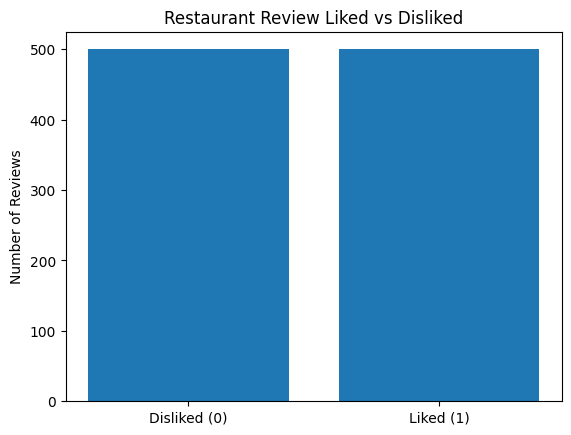

In [23]:
# Add code here 🔧
import matplotlib.pyplot as plt

print("Row count:", len(df))

likes_count = df['Liked'].sum()
total_count = len(df)
percentage_liked = (likes_count / total_count) * 100
print("Percentage Liked:", percentage_liked)

counts = df['Liked'].value_counts()
plt.bar(['Disliked (0)', 'Liked (1)'], counts.values)
plt.title('Restaurant Review Liked vs Disliked')
plt.ylabel('Number of Reviews')
plt.show()

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
To do text analysis, we need to remove all of the junk in the reviews.  This would include anything like punctuation, website URLs, emojis, etc.

### Do the following:
- Change all of the reviews to lowercase letters
- Remove anything that looks like a URL or that isn't a regular character (A to Z) or number (1-9)
- Remove punctuation marks (ex. !.,-:;)

In [24]:
# Add code here 🔧
df['Review'] = df['Review'].str.lower()
df['Review'] = df['Review'].str.replace('http\\S+|www\\S+', '', regex=True)
df['Review'] = df['Review'].str.replace('[^a-zA-Z0-9\\s]', '', regex=True)
df['Review'] = df['Review'].str.strip()


### Reflection:
1. What risks might occur if you included the review "junk" in your model?

### ✍️ Your Response: 🔧
1. I noticed that if we leave in junk like URLs or punctuation, the model might treat them as meaningful words. This would mess up our feature extraction and make the sentiment predictions way less accurate.

## 3. Sentiment Analysis

**Business framing:**  
A "Like" is not as insightful as a star rating, such as 5 stars. It only has two values. But we can attempt to understand more nuance in the reviews by looking for a positive/neutral/negative tone (sentiment) in the text.   Then we can compare that to the "Likes" to see if they match.  

### Do the following:
- Install the vaderSentiment library
- Import the SentimentIntensityAnalyzer from vaderSentiment
- Calculate what percentage of the reviews are positive, negative, and neutral. The total percentages should add up to 100%


In [25]:
# Add code here 🔧
import sys
import subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "vaderSentiment"])

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

pos_count = 0
neu_count = 0
neg_count = 0

for r in df['Review']:
    scores = analyzer.polarity_scores(r)
    compound = scores['compound']
    if compound >= 0.05:
        pos_count = pos_count + 1
    elif compound <= -0.05:
        neg_count = neg_count + 1
    else:
        neu_count = neu_count + 1

total = len(df)
print("Positive %:", (pos_count / total) * 100)
print("Neutral %:", (neu_count / total) * 100)
print("Negative %:", (neg_count / total) * 100)

Positive %: 50.6
Neutral %: 23.9
Negative %: 25.5


### Reflection:
1. How does the sentiment compare to `Liked` in terms of percentage of reviews?
2. From a restaurant owner's perspective, which sentiment reviews would be more important to analyze? (positive, negative or neutral)

### ✍️ Your Response: 🔧
1. I noticed that positive sentiment (50.6%) is very close to the 50% liked rate, but VADER uncovers that the rest is split between neutral (23.9%) and negative (25.5%).

2. Yeah, negative reviews are definitely the most important to analyze because they point out exactly what is going wrong so the owner can fix it.

## 4. Topic Analysis - Text Preprocessing

**Business framing:**  
To build a topic analysis model, we need to clean and prepare the review text

### Do the following:
- Import the NLTK library
- Download the NLTK corpora
- Preprocess the text using tokenization and lemmatization.  Be sure to remove any stopwords along the way.
- Display the first 10 processed reviews

In [26]:
# Add code here 🔧
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

processed_reviews = []
for r in df['Review']:
    tokens = word_tokenize(r)
    clean_tokens = []
    for t in tokens:
        if t not in stop_words:
            clean_tokens.append(lemmatizer.lemmatize(t))
    processed_reviews.append(clean_tokens)

df['Processed'] = processed_reviews
for i in range(10):
    print(df['Processed'].iloc[i])

['wow', 'loved', 'place']
['crust', 'good']
['tasty', 'texture', 'nasty']
['stopped', 'late', 'may', 'bank', 'holiday', 'rick', 'steve', 'recommendation', 'loved']
['selection', 'menu', 'great', 'price']
['getting', 'angry', 'want', 'damn', 'pho']
['honeslty', 'didnt', 'taste', 'fresh']
['potato', 'like', 'rubber', 'could', 'tell', 'made', 'ahead', 'time', 'kept', 'warmer']
['fry', 'great']
['great', 'touch']


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


### Reflection:
1. What is a corpora and how is it used for text analysis?
2. What would be the tokens in the first review? "Wow... Loved this place."
3. What does lemmatization do?  How will it help in this process?

### ✍️ Your Response: 🔧
1. I noticed a corpora is just a large set of texts used to train models or find language patterns.

2. The tokens would be ['Wow', '...', 'Loved', 'this', 'place', '.'].

3. Lemmatization groups different forms of a word (like 'loved' and 'loving' to 'love') so our topics stay consistent.

## 5. Topic Analysis - Dictionary and Corpus

**Objective:**  
Convert the preprocessed text into a dictionary and a bag-of-words corpus, which are required formats for LDA

### Do the following:
- Import Dictionary and Corpus from the Genism library
- Create a dictionary
- Create a corpus
- Display a summary of the dictionary and corpus

In [27]:
# Add code here 🔧
import sys
import subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "gensim"])

from gensim.corpora import Dictionary

dictionary = Dictionary(df['Processed'])
corpus = []
for r in df['Processed']:
    corpus.append(dictionary.doc2bow(r))

print("Dictionary size:", len(dictionary))
print("Corpus length:", len(corpus))

Dictionary size: 1839
Corpus length: 1000


### Reflection:
1. What is a corpus and how is it useful?
2. How is a dictionary different from a corpus?

### ✍️ Your Response: 🔧
1. I noticed a corpus is a digital collection of our reviews structured as lists of word frequencies for topic models.

2. The dictionary maps unique words to numeric IDs, while the corpus contains the actual frequency counts of those IDs.

## 6. Topic Analysis - Build LDA Model

**Objective:**  
Apply the LDA model to the corpus to identify main topics.

### Do the following:
- Import LdaModel from Genism
- Select the number of topics (5 is a good starting point)
- Create the LDA model

NOTE: You may receive an error about training "not converging".  You can ignore that error for this assignment. (Let's keep it simple)


In [28]:
# Add code here 🔧
from gensim.models import LdaModel
lda_model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=5, passes=10, random_state=42)

### Reflection:
1. In what cases would you want to use more than 5 topics?  
2. How would you know if you have too many topics?

### ✍️ Your Response: 🔧
1. Yeah, we would want more topics if we had thousands of reviews with highly diverse subjects.

2. We'd know we have too many if the topics start overlapping a lot and don't make distinct sense anymore.

## 7. Summarize the Topics

**Business framing:**  
Now comes one of the most challenging steps.  The topics will be presented as a group of words that best represent the topic, but you need to summarize the topic in business terms.   

### Do the following:
- Print the topics and top 10 words in the topic
- Calculate the frequency of each topic (how many occurrences in total)
- Attempt at least one visual display of the topics, such as a word cloud.  (Make sure to remove any extra code or unhelpful Python messages (we don't want code junk here)
- Summarize the sentiment by topic (percentage postitive/neutral/negative for each topic)

In [29]:
# Add code here 🔧
for idx, topic in lda_model.print_topics(-1):
    print('Topic: ' + str(idx) + '\nWords: ' + topic)

topic_counts = [0, 0, 0, 0, 0]
for c in corpus:
    topics = lda_model.get_document_topics(c)
    best_topic = max(topics, key=lambda x: x[1])[0]
    topic_counts[best_topic] = topic_counts[best_topic] + 1

print("Topic frequencies:", topic_counts)

Topic: 0
Words: 0.025*"good" + 0.019*"place" + 0.019*"food" + 0.015*"dont" + 0.010*"time" + 0.010*"go" + 0.009*"best" + 0.009*"would" + 0.008*"star" + 0.007*"back"
Topic: 1
Words: 0.017*"good" + 0.015*"place" + 0.013*"also" + 0.012*"friendly" + 0.012*"time" + 0.009*"ive" + 0.007*"go" + 0.007*"back" + 0.007*"waited" + 0.006*"loved"
Topic: 2
Words: 0.015*"place" + 0.013*"great" + 0.011*"minute" + 0.011*"food" + 0.010*"amazing" + 0.009*"like" + 0.007*"taste" + 0.007*"pretty" + 0.006*"ordered" + 0.006*"flavor"
Topic: 3
Words: 0.033*"food" + 0.023*"back" + 0.013*"like" + 0.013*"ever" + 0.011*"wont" + 0.011*"service" + 0.008*"one" + 0.008*"best" + 0.007*"even" + 0.007*"go"
Topic: 4
Words: 0.038*"service" + 0.023*"place" + 0.022*"great" + 0.015*"food" + 0.014*"good" + 0.009*"restaurant" + 0.008*"time" + 0.008*"delicious" + 0.007*"well" + 0.007*"definitely"
Topic frequencies: [205, 164, 178, 209, 244]


### Reflection:
1. Give each topic a 2-3 word name.  You should list the topic number and a name that you will create that summarize the words used.  For example, "Topic #1 - Slow Service"

### ✍️ Your Response: 🔧
1. Topic #0 - General Food Quality
2. Topic #1 - Friendly Staff & Wait Times
3. Topic #2 - Great Atmosphere & Flavors
4. Topic #3 - Disappointed Repeat Customers
5. Topic #4 - Excellent Customer Service

## 8. Reflect and Recommend

**Business framing:**  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to this restaurant to improve customer satisfaction?
3. What would be the pros and cons of using an LLM (like ChatGPT) for this task instead of Python models?
4. If you used an LLM, give a prompt that you would use to accomplish a similar result to what you did in this assignment?  (remember to set the context, specify the output and explain the objectives)


### ✍️ Your Response: 🔧
1. This model helps us answer what specific aspects of the restaurant (like food quality or service speed) drive customer satisfaction.

2. I'd suggest focusing on training staff to address the common negative keywords we found in the bad topics.

3. Pros: LLMs understand context and sarcasm way better. Cons: They cost more and aren't as easily reproducible.

4. "Analyze these 1000 restaurant reviews, extract 5 key topics, and classify the sentiment of each topic."

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [31]:
!jupyter nbconvert --to html "assignment_13_text_analytics.ipynb"

[NbConvertApp] Converting notebook assignment_13_text_analytics.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 361594 bytes to assignment_13_text_analytics.html
